In [1]:
#Explore child mortality
# Reads: ../data/child-mortality.csv

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sns.set_theme(style="whitegrid")

The link up to my project

Child mortality is one of your two health measures. The  question is whether richer countries have lower rates, along with longer life expectancy.

In [3]:
# Load
mort = pd.read_csv(r"C:\Users\admin\Desktop\Captoneproject-pydata\data\child-mortality.csv")
print("Original columns:", mort.columns.tolist())
mort = mort.rename(columns={"Under-five mortality rate (selected)": "child_mort"})


Original columns: ['Entity', 'Code', 'Year', 'Under-five mortality rate (selected)']


In [4]:
    # First look
print("\nHEAD")
display(mort.head())
print("\nTAIL")
display(mort.tail())
print("\nSAMPLE")
display(mort.sample(8, random_state=1))


HEAD


,Entity,Code,Year,child_mort
0,Afghanistan,AFG,1957,36.82
1,Afghanistan,AFG,1958,36.21
2,Afghanistan,AFG,1959,35.64
3,Afghanistan,AFG,1960,35.06
4,Afghanistan,AFG,1961,34.52



TAIL


,Entity,Code,Year,child_mort
17061,Zimbabwe,ZWE,2020,6.17
17062,Zimbabwe,ZWE,2021,6.24
17063,Zimbabwe,ZWE,2022,6.40
17064,Zimbabwe,ZWE,2023,6.42
17065,Zimbabwe,ZWE,2024,6.47



SAMPLE


,Entity,Code,Year,child_mort
10390,Nepal,NPL,1954,34.03
11314,Norway,NOR,1880,15.21
2573,Cameroon,CMR,2014,9.24
8470,Lebanon,LBN,1969,6.07
227,Algeria,DZA,2012,2.66
3471,Costa Rica,CRI,1985,2.20
13795,Somalia,SOM,2008,16.67
12925,Saint Vincent and the Grenadines,VCT,2017,1.58


In [5]:
# Structure
print("\nSHAPE (rows, columns)")
print(mort.shape)
print("\nDTYPES")
print(mort.dtypes)
print("\nINFO")
mort.info()
print("\nMISSING VALUES")
print(mort.isna().sum())
print("\nDUPLICATE ROWS")
print(mort.duplicated().sum())


SHAPE (rows, columns)
(17066, 4)

DTYPES
Entity            str
Code              str
Year            int64
child_mort    float64
dtype: object

INFO
<class 'pandas.DataFrame'>
RangeIndex: 17066 entries, 0 to 17065
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Entity      17066 non-null  str    
 1   Code        17066 non-null  str    
 2   Year        17066 non-null  int64  
 3   child_mort  17066 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 730.5 KB

MISSING VALUES
Entity        0
Code          0
Year          0
child_mort    0
dtype: int64

DUPLICATE ROWS
0


In [6]:
# Coverage
print("\nCOVERAGE")
print("Entities:", mort["Entity"].nunique())
print("Years:", mort["Year"].min(), "to", mort["Year"].max())



COVERAGE
Entities: 213
Years: 1751 to 2024


In [7]:
    # Separate aggregates (World, regions) from real countries
is_aggregate = mort["Code"].isna() | mort["Code"].astype(str).str.startswith("OWID")
print("Aggregate rows (not countries):", is_aggregate.sum())
print("Country rows:", (~is_aggregate).sum())
print("Some aggregate names:", sorted(mort.loc[is_aggregate, "Entity"].unique())[:12])
countries = mort[~is_aggregate].copy()

Aggregate rows (not countries): 905
Country rows: 16161
Some aggregate names: ['Africa', 'Asia', 'Europe', 'European Union (27)', 'High-income countries', 'Kosovo', 'Low-income countries', 'Lower-middle-income countries', 'North America', 'Oceania', 'South America', 'Upper-middle-income countries']


In [8]:
# Check the unit: look at the range of values
print("\nUNIT CHECK")
print("Min:", round(countries["child_mort"].min(), 3), "| Max:", round(countries["child_mort"].max(), 3))
print("Values this small and this large suggest a percentage of children (per 100 births).")
print("Confirm on the Our World in Data chart page before labelling charts.")



UNIT CHECK
Min: 0.13 | Max: 78.09
Values this small and this large suggest a percentage of children (per 100 births).
Confirm on the Our World in Data chart page before labelling charts.


In [9]:
# Centre and spread
print("\nDESCRIBE (countries only)")
print(countries["child_mort"].describe().round(2))

mean_ = countries["child_mort"].mean()
median_ = countries["child_mort"].median()
std_ = countries["child_mort"].std()
skew_ = countries["child_mort"].skew()
print(f"\nMean:   {mean_:.2f}")
print(f"Median: {median_:.2f}")
print(f"Std:    {std_:.2f}")
print(f"Skew:   {skew_:.2f}  (negative = tail to the left, positive = tail to the right)")



DESCRIBE (countries only)
count    16161.00
mean        10.57
std         10.61
min          0.13
25%          2.12
50%          6.47
75%         16.62
max         78.09
Name: child_mort, dtype: float64

Mean:   10.57
Median: 6.47
Std:    10.61
Skew:   1.26  (negative = tail to the left, positive = tail to the right)


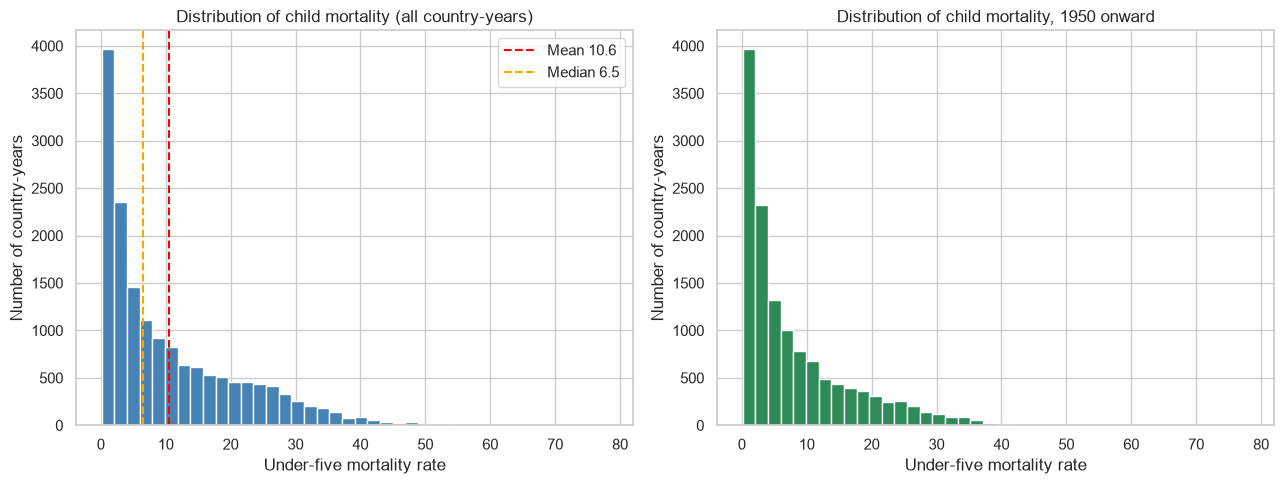

In [10]:
    # Distribution plots
since_1950 = countries[countries["Year"] >= 1950]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(countries["child_mort"], bins=40, color="steelblue", edgecolor="white")
axes[0].axvline(mean_, color="red", linestyle="--", label=f"Mean {mean_:.1f}")
axes[0].axvline(median_, color="orange", linestyle="--", label=f"Median {median_:.1f}")
axes[0].set_title("Distribution of child mortality (all country-years)")
axes[0].set_xlabel("Under-five mortality rate")
axes[0].set_ylabel("Number of country-years")
axes[0].legend()

axes[1].hist(since_1950["child_mort"], bins=40, color="seagreen", edgecolor="white")
axes[1].set_title("Distribution of child mortality, 1950 onward")
axes[1].set_xlabel("Under-five mortality rate")
axes[1].set_ylabel("Number of country-years")

plt.tight_layout()
plt.show()

### Charts 1 and 2: Distribution of child mortality

HISTO ALL BY COUNTRIES: Right-skewed, continuous

CHART 2
Same, for the analysis period

**What they show:** each bar counts how many country-years (one country in one year) fall in that range of the under-five mortality rate. The left chart uses all country-years. The right chart uses 1950 onward only. The red dashed line is the mean (10.6) and the orange dashed line is the median (6.5).

**Type of distribution:** right-skewed (skew = 1.26). Most country-years have a low child mortality rate, but a few have a very high rate, which stretches the chart to the right.

**Why the mean is above the median:** the few very high values pull the average up, while the median stays near the middle of the data. Because of this, the median describes a typical country-year better than the mean.

**Why the two charts look alike:** roughly 80% of the country rows are from 1950 onward, so removing the earlier rows changes the shape very little.

**What it tells me:** child mortality is low for most country-years, but a minority had very high rates. A bell-curve assumption would be wrong here, so I should use the median and rank-based measures (such as Spearman correlation) in the analysis.

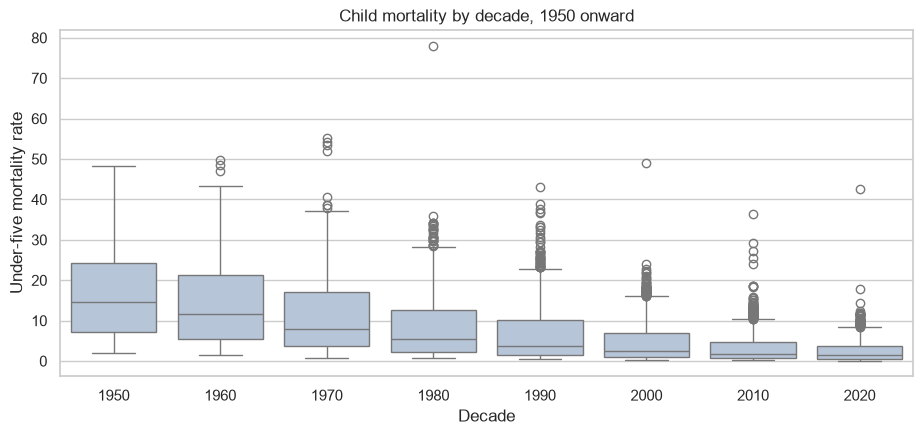

In [11]:
# Spread over time
countries["decade"] = (countries["Year"] // 10) * 10
recent = countries[countries["Year"] >= 1950]

plt.figure(figsize=(11, 4.5))
sns.boxplot(data=recent, x="decade", y="child_mort", color="lightsteelblue")
plt.title("Child mortality by decade, 1950 onward")
plt.xlabel("Decade")
plt.ylabel("Under-five mortality rate")
plt.show()

###  Child mortality by decade, 1950 onward

**What it shows:** each box covers the middle 50% of country-years in a decade, the line inside is the median, the whiskers show the typical range, and the dots are outliers.

**Trend:** the boxes drop steadily. The median falls from roughly 14 to 15 in the 1950s to around 1 or 2 in the 2020s, so child mortality fell across the world.

**Spread:** the boxes also get much narrower, so countries became more alike over time.

**Outliers:** every decade has dots far above the box, which are country-years with very high child mortality. The highest point on the chart, close to 80, is in the 1980s. I have not checked which country it is, so I will not state a cause.

**Caution:** the 2020s box covers only 2020 to 2024, so it has fewer years than the other decades.

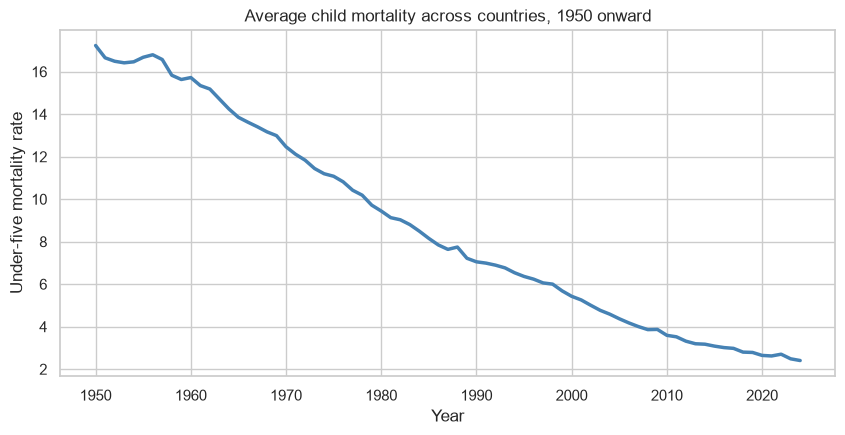

In [12]:
# average child mortality by year
avg_by_year = recent.groupby("Year")["child_mort"].mean()

plt.figure(figsize=(10, 4.5))
plt.plot(avg_by_year.index, avg_by_year.values, color="steelblue", linewidth=2.5)
plt.title("Average child mortality across countries, 1950 onward")
plt.xlabel("Year")
plt.ylabel("Under-five mortality rate")
plt.show()

### Average child mortality across countries, 1950 onward

**What it shows:** each point is the simple average of child mortality across all countries in that year.

**Trend:** the line falls from about 17 in 1950 to about 2.4 in 2024, a very large drop, with only small flat patches in the 1950s.

**Why it matters for my question:** child mortality fell almost everywhere over time, just as life expectancy rose. Part of any link with GDP could come from both moving with time, so I should look at differences between countries within the same year, not only overall trends.

**Note:** this is an average where every country counts equally, so it is not the world rate.

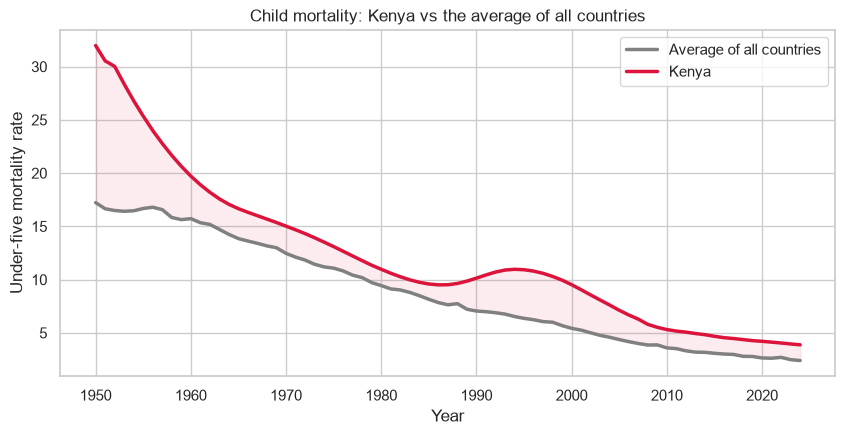

In [13]:
# Kenya vs the average of all countries
kenya = recent[recent["Entity"] == "Kenya"].set_index("Year")["child_mort"]
compare = pd.DataFrame({"Kenya": kenya, "Average of all countries": avg_by_year}).dropna()

plt.figure(figsize=(10, 4.5))
plt.plot(compare.index, compare["Average of all countries"], color="gray", linewidth=2.5, label="Average of all countries")
plt.plot(compare.index, compare["Kenya"], color="crimson", linewidth=2.5, label="Kenya")
plt.fill_between(compare.index, compare["Kenya"], compare["Average of all countries"], color="crimson", alpha=0.08)
plt.title("Child mortality: Kenya vs the average of all countries")
plt.xlabel("Year")
plt.ylabel("Under-five mortality rate")
plt.legend()
plt.show()

### Child mortality, Kenya vs the average of all countries

**What it shows:** the grey line is the average of all countries, the red line is Kenya, and the pink band is the gap between them.

**Kenya is above the average in every year since 1950**, which means higher child mortality than the typical country. It started at about 32, compared with about 17 for the average.

**Catching up, then a setback:** Kenya's rate fell fast until the mid-1980s, when the gap was only about 1 point (closest in 1983). It then rose again in the late 1980s and early 1990s while the average kept falling, and the gap widened.

**Recovery:** from the mid-1990s Kenya's rate fell again, and ended at about 3.9, still above the average of about 2.4.

**What I cannot say:** the data shows when the setback happened, but not why. I will not state a cause unless I find a source.